In [1]:
import sys
from google.colab import drive

drive.mount('/content/drive')
sys.path.insert(0, '/content/drive/MyDrive/predictive_learning')

import networks
from networks import LateralInhibitoryLayer
import generators
from generators import MovingMNIST32, CatCamPatch16
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output
from tqdm import tqdm
from IPython.display import display



def cosine_similarity(a, b):
  return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

def train_network(network, vg, num_steps, num_tests, sequence_size, eval_every):
  #save results
  synaptic_input_distance_from_identity_perceptron = []
  distance_from_identity_perceptron = []
  consistency_error_perceptron = []
  second_moment_estimate_perceptron = []
  mse_error_perceptron = []

  # Create persistent display handles
  plot_handle_rf = None
  plot_handle_seq = None
  plot_handle_err = None

  fig, ax = plt.subplots(figsize=(10, 4))
  plt.close(fig)  # Close to prevent initial empty duplicate display

  #network.lr_w = 0.0005
  #network.lr_m = 0.001
  for i in tqdm(range(num_steps), desc="Training Progress"):
      if i % eval_every == 0:
          examples = []
          examples_input = []
          errors = []

          # We will capture one specific test sequence to visualize completion
          visualize_sequence_input = []
          visualize_sequence_reconstructed = []
          visualize_sequence_gradients = []

          for j in range(num_tests):
              vg.set_random_position()
              network.reset_network()

              test_inputs = []
              test_reconstructed = []
              test_gradients = []

              for sequence_step in range(sequence_size//2):
                  vg.set_next_position()
                  x = vg.get_current_frame().flatten()
                  network.new_epoch()
                  network.update_activations(x, False)
                  examples.append(network.y.copy())
                  errors.append(1-cosine_similarity(x, network.projection().flatten()))
                  examples_input.append(network.w @ x)

                  if j == 0:
                      test_inputs.append(x.copy())
                      test_reconstructed.append(network.projection().copy())
                      test_gradients.append(getattr(network, 'y_gradient_track', np.zeros(1)).copy())

              for sequence_step in range(sequence_size//2, sequence_size):
                  vg.set_next_position()
                  x = vg.get_blind_frame().flatten()
                  true_x = vg.get_current_frame().flatten()
                  network.new_epoch()
                  network.update_activations(x, False)
                  examples.append(network.y.copy())
                  errors.append(1-cosine_similarity(true_x, network.projection().flatten()))
                  examples_input.append(network.w @ x)

                  if j == 0:
                      test_inputs.append(x.copy())
                      test_reconstructed.append(network.projection().copy())
                      test_gradients.append(getattr(network, 'y_gradient_track', np.zeros(1)).copy())

              if j == 0:
                  visualize_sequence_input = test_inputs
                  visualize_sequence_reconstructed = test_reconstructed
                  visualize_sequence_gradients = test_gradients

          synaptic_input_distance_from_identity_perceptron.append(np.linalg.norm(np.cov(np.array(examples_input), rowvar=False) - np.eye(network.m.shape[0]), ord='fro'))
          current_second_moment_estimate = np.cov(np.array(examples), rowvar=False)
          distance_from_identity_perceptron.append(np.linalg.norm(network.m - np.eye(network.m.shape[0]), ord='fro'))
          consistency_error_perceptron.append(np.linalg.norm((network.w @ network.w.T) - (current_second_moment_estimate), ord='fro'))
          second_moment_estimate_perceptron.append(np.linalg.norm(current_second_moment_estimate - np.eye(network.m.shape[0]), ord='fro'))
          mse_error_perceptron.append(np.mean(errors))

          # Clear and update error plot
          ax.cla()
          ax.semilogy(np.array(mse_error_perceptron), alpha=0.8, color='steelblue')
          ax.set_title(f"Reconstruction Error (step {i + 1} / {num_steps})")
          ax.set_xlabel("Simulation Steps")
          ax.set_ylabel("Mean Squared Error")

          # Plot a few receptive fields during training
          num_show = min(8, network.w.shape[0])
          fig_rf, rf_axes = plt.subplots(1, num_show, figsize=(3 * num_show, 6))
          if num_show == 1:
              rf_axes = [rf_axes]

          sorted_indices = np.argsort(np.linalg.norm(network.w, axis=1))[::-1]  # Sort by norm of weights
          for j in range(num_show):
              rf_img = network.w[sorted_indices[j]].reshape(vg.x_size, vg.y_size)
              vmax = np.max(np.abs(rf_img))
              rf_axes[j].imshow(rf_img, cmap='gray', vmin=0, vmax=vmax)
              rf_axes[j].set_title(f"RF {j}")
              rf_axes[j].axis("off")

          fig_rf.suptitle(f"Receptive Fields (step {i + 1})")
          plt.tight_layout()

          # Generate sequence completion plot
          fig_seq, seq_axes = plt.subplots(3, sequence_size, figsize=(2.5 * sequence_size, 7.5))
          for col in range(sequence_size):
              # Row 0: Inputs
              img_in = visualize_sequence_input[col].reshape(vg.x_size, vg.y_size)
              seq_axes[0, col].imshow(img_in, cmap='gray', vmin=0, vmax=1)
              seq_axes[0, col].axis('off')
              if col == 0:
                  seq_axes[0, col].set_ylabel("Input x", fontsize=12, labelpad=15)
                  seq_axes[0, col].axis('on')
                  seq_axes[0, col].set_xticks([])
                  seq_axes[0, col].set_yticks([])

              # Row 1: Reconstruction
              img_recon = visualize_sequence_reconstructed[col].reshape(vg.x_size, vg.y_size)
              vmax_recon = max(0.01, np.max(img_recon))
              seq_axes[1, col].imshow(img_recon, cmap='gray', vmin=0, vmax=vmax_recon)
              seq_axes[1, col].axis('off')
              if col == 0:
                  seq_axes[1, col].set_ylabel("Projection", fontsize=12, labelpad=15)
                  seq_axes[1, col].axis('on')
                  seq_axes[1, col].set_xticks([])
                  seq_axes[1, col].set_yticks([])

              # Row 2: Gradient Magnitude
              grad = np.abs(visualize_sequence_gradients[col])
              seq_axes[2, col].plot(grad, color='crimson')
              seq_axes[2, col].set_ylim(bottom=0)
              if col == 0:
                  seq_axes[2, col].set_ylabel("Gradient Mag", fontsize=12)
              else:
                  seq_axes[2, col].set_yticklabels([])
              seq_axes[2, col].set_xlabel(f"t={col+1}")

          fig_seq.suptitle(f"Sequence Completion & Inference Gradients (step {i + 1})", fontsize=14)
          plt.tight_layout()

          # Display or update plots using display handles
          if plot_handle_rf is None:
              plot_handle_rf = display(fig_rf, display_id=True)
              plot_handle_seq = display(fig_seq, display_id=True)
              plot_handle_err = display(fig, display_id=True)
          else:
              plot_handle_rf.update(fig_rf)
              plot_handle_seq.update(fig_seq)
              plot_handle_err.update(fig)

          plt.close(fig_rf)
          plt.close(fig_seq)

      vg.set_random_position()
      network.reset_activations()
      for sequence_step in range(sequence_size):
          vg.set_next_position()
          x = vg.get_current_frame().flatten()
          network.new_epoch()
          network.update_activations(x, True)
          network.update_counts()
          network.update_parameters(['m', 'w', 'p'])


  plt.xlim(-5, 5)
  plt.ylim(-5, 5)
  plt.show()

  plt.plot(distance_from_identity_perceptron)
  plt.xlabel('Iterations')
  plt.ylabel('Distance from Identity')
  plt.show()

  plt.plot(consistency_error_perceptron)
  plt.xlabel('Iterations')
  plt.ylabel('Consistency Error')
  plt.show()

  plt.plot(second_moment_estimate_perceptron)
  plt.xlabel('Iterations')
  plt.ylabel('Output distance from Identity')
  plt.show()

  plt.plot(mse_error_perceptron)
  plt.xlabel('Iterations')
  plt.ylabel('MSE Error')
  plt.show()

  plt.plot(synaptic_input_distance_from_identity_perceptron)
  plt.xlabel('Iterations')
  plt.ylabel('Synaptic Input Distance from Identity')
  plt.show()

Mounted at /content/drive


# CATCAM dataset (16x16 whitened on/off patches)

Natural videos, taken by a camera attached to a cat's head (https://pubmed.ncbi.nlm.nih.gov/14762723/). We extract a patch, whiten it with ZCA and split it into on off channels

First download and store videos in directory if they dont exist

In [2]:
import os
import tarfile
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

directory = '/content/drive/MyDrive/catcam_movies'
# Create directory for movies
os.makedirs(directory, exist_ok=True)

# Download first 10 movies
for i in range(1, 11):
    movie_name = f"movie{i:02d}.tar"
    url = f"https://zenodo.org/records/46481/files/{movie_name}?download=1"
    dest_path = os.path.join(directory, movie_name)

    if not os.path.exists(dest_path):
        print(f"Downloading {movie_name}...")
        urllib.request.urlretrieve(url, dest_path)

    # Extract tar file
    extract_dir = os.path.join(directory, f"movie{i:02d}")
    if not os.path.exists(extract_dir):
        print(f"Extracting {movie_name}...")
        with tarfile.open(dest_path) as tar:
            tar.extractall(path=extract_dir)

print("Download and extraction completed!")

# Load and display an example frame from movie01
movie1_dir = os.path.join(directory, 'movie01')
# Find the first image/frame file
frame_files = sorted([f for f in os.listdir(movie1_dir) if f.endswith(('.png', '.jpg', '.jpeg', '.pgm', '.ppm')) or 'frame' in f])

if frame_files:
    img_path = os.path.join(movie1_dir, frame_files[0])
    img = plt.imread(img_path)

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(img, cmap='gray')

    # Calculate middle coordinates for 16x16 patch
    height, width = img.shape[:2]
    patch_size = 16
    start_x = (width - patch_size) // 2
    start_y = (height - patch_size) // 2

    # Add a red square patch
    rect = patches.Rectangle((start_x, start_y), patch_size, patch_size, linewidth=2, edgecolor='r', facecolor='none')
    ax.add_patch(rect)

    ax.set_title(f"Example Frame: {frame_files[0]} with 16x16 Patch")
    plt.axis('off')
    plt.show()
else:
    # If files are raw binary matrices instead of standard images
    all_files = sorted(os.listdir(movie1_dir))
    print(f"Extracted files in movie01: {all_files[:10]}")


Download and extraction completed!
Extracted files in movie01: ['labelb000530a']


Example of video playing. Red patch is the video we extract and process.


In [3]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
from PIL import Image

# Path to the movie frames
movie_seq_dir = '/content/drive/MyDrive/catcam_movies/movie01/labelb000530a'

if os.path.exists(movie_seq_dir) and os.path.isdir(movie_seq_dir):
    frames = sorted(os.listdir(movie_seq_dir))

    # Select a segment of 100 frames to play as a video clip
    start_frame = 100
    num_frames = 100
    selected_frames = frames[start_frame:start_frame + num_frames]

    # Set up the figure and axis for animation
    fig, ax = plt.subplots(figsize=(6, 6))
    plt.axis('off')

    # Load first frame to initialize
    first_frame_path = os.path.join(movie_seq_dir, selected_frames[0])
    with Image.open(first_frame_path) as img_file:
        img_data = np.array(img_file, dtype=np.float32)

    im = ax.imshow(img_data, cmap='gray', vmin=img_data.min(), vmax=img_data.max())

    # Create the central 16x16 red square patch
    height, width = img_data.shape[:2]
    patch_size = 16
    start_x = (width - patch_size) // 2
    start_y = (height - patch_size) // 2

    rect = patches.Rectangle((start_x, start_y), patch_size, patch_size, linewidth=2, edgecolor='r', facecolor='none')
    ax.add_patch(rect)

    title = ax.set_title(f"Playing Movie Sequence (Frame {start_frame})")

    def update(frame_idx):
        frame_name = selected_frames[frame_idx]
        frame_path = os.path.join(movie_seq_dir, frame_name)

        with Image.open(frame_path) as img_file:
            img = np.array(img_file, dtype=np.float32)

        im.set_array(img)
        im.set_clim(vmin=img.min(), vmax=img.max())
        title.set_text(f"Playing Movie Sequence (Frame {start_frame + frame_idx})")
        return [im, rect, title]

    # Create and render the animation as an HTML5 video
    ani = FuncAnimation(fig, update, frames=len(selected_frames), interval=50, blit=True)
    plt.close(fig)
    display(HTML(ani.to_html5_video()))
else:
    print(f"Directory does not exist: {movie_seq_dir}")

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# Initialize the CatCamPatch16 generator
vg = CatCamPatch16(directory="/content/drive/MyDrive/catcam_movies",
                    num_movies=10,
                    patch_size=16,
                    download=True,
                    whiten_samples=5000)

# Select a random starting frame and position in the video files
vg.set_random_position()


In [ ]:
# Select a random starting frame and position in the video files
vg.set_random_position()

# Capture a sequence of 60 frames using set_next_position()
num_frames = 60
rgb_sequence = []

for i in range(num_frames):
    vg.set_next_position()
    frame = vg.get_current_frame()

    onoff_frame = 1 * np.vstack([frame * (frame > 0), -frame * (frame < 0)])
    rf_img = onoff_frame.reshape(vg.x_size * 2, vg.y_size)

    # Split into ON and OFF channels
    on_channel = rf_img[:vg.x_size, :]
    off_channel = rf_img[vg.x_size:, :]

    # Normalize each channel individually to [0, 1] for visualization
    max_on = np.max(on_channel) if np.max(on_channel) > 0 else 1.0
    max_off = np.max(off_channel) if np.max(off_channel) > 0 else 1.0

    norm_on = on_channel / max_on
    norm_off = off_channel / max_off

    # Create an RGB image where Red = ON, Blue = OFF, Green = 0
    rgb_img = np.zeros((vg.x_size, vg.y_size, 3))
    rgb_img[..., 0] = norm_on.reshape((vg.x_size, vg.y_size))   # Red channel
    rgb_img[..., 2] = norm_off.reshape((vg.x_size, vg.y_size))  # Blue channel

    rgb_sequence.append(rgb_img)

# Setup the figure and axis for displaying the video clip
fig, ax = plt.subplots(figsize=(4, 4))
ax.axis('off')

# Initialize the frame plot with the first captured patch
im = ax.imshow(rgb_sequence[0])
title = ax.set_title("CatCamPatch16 | Frame 1 (Red: ON, Blue: OFF)")

def update(idx):
    im.set_data(rgb_sequence[idx])
    title.set_text(f"CatCamPatch16 | Frame {idx + 1} (Red: ON, Blue: OFF)")
    return [im, title]

# Generate and embed the 60-frame video animation (slower: interval = 200 ms)
ani = FuncAnimation(fig, update, frames=num_frames, interval=200, blit=True)
plt.close(fig)
HTML(ani.to_html5_video())

Fitting zca whitening on 5000 patches...


Training Progress:   0%|          | 0/10000 [00:00<?, ?it/s]/tmp/ipykernel_15166/1338896386.py:20: RuntimeWarning: invalid value encountered in scalar divide
  return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))


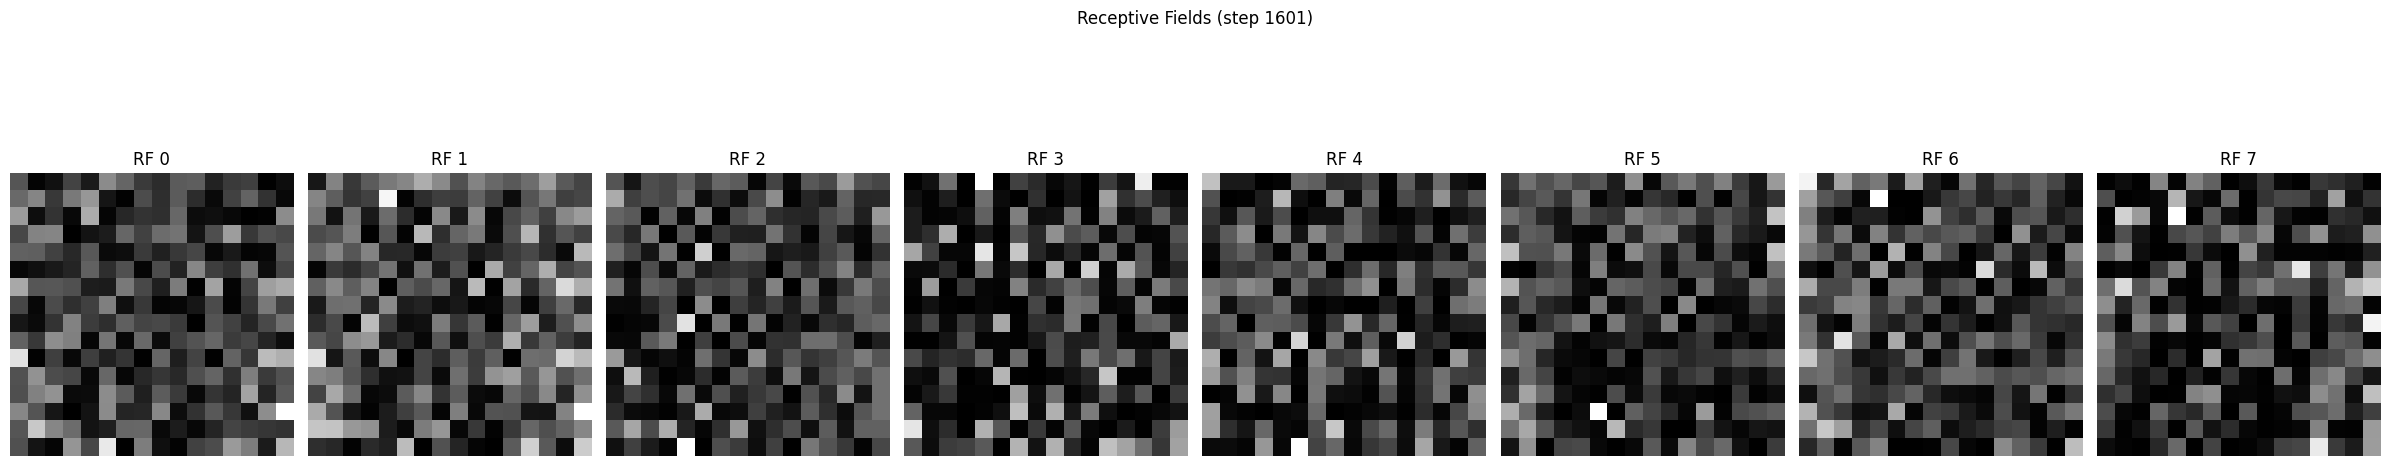

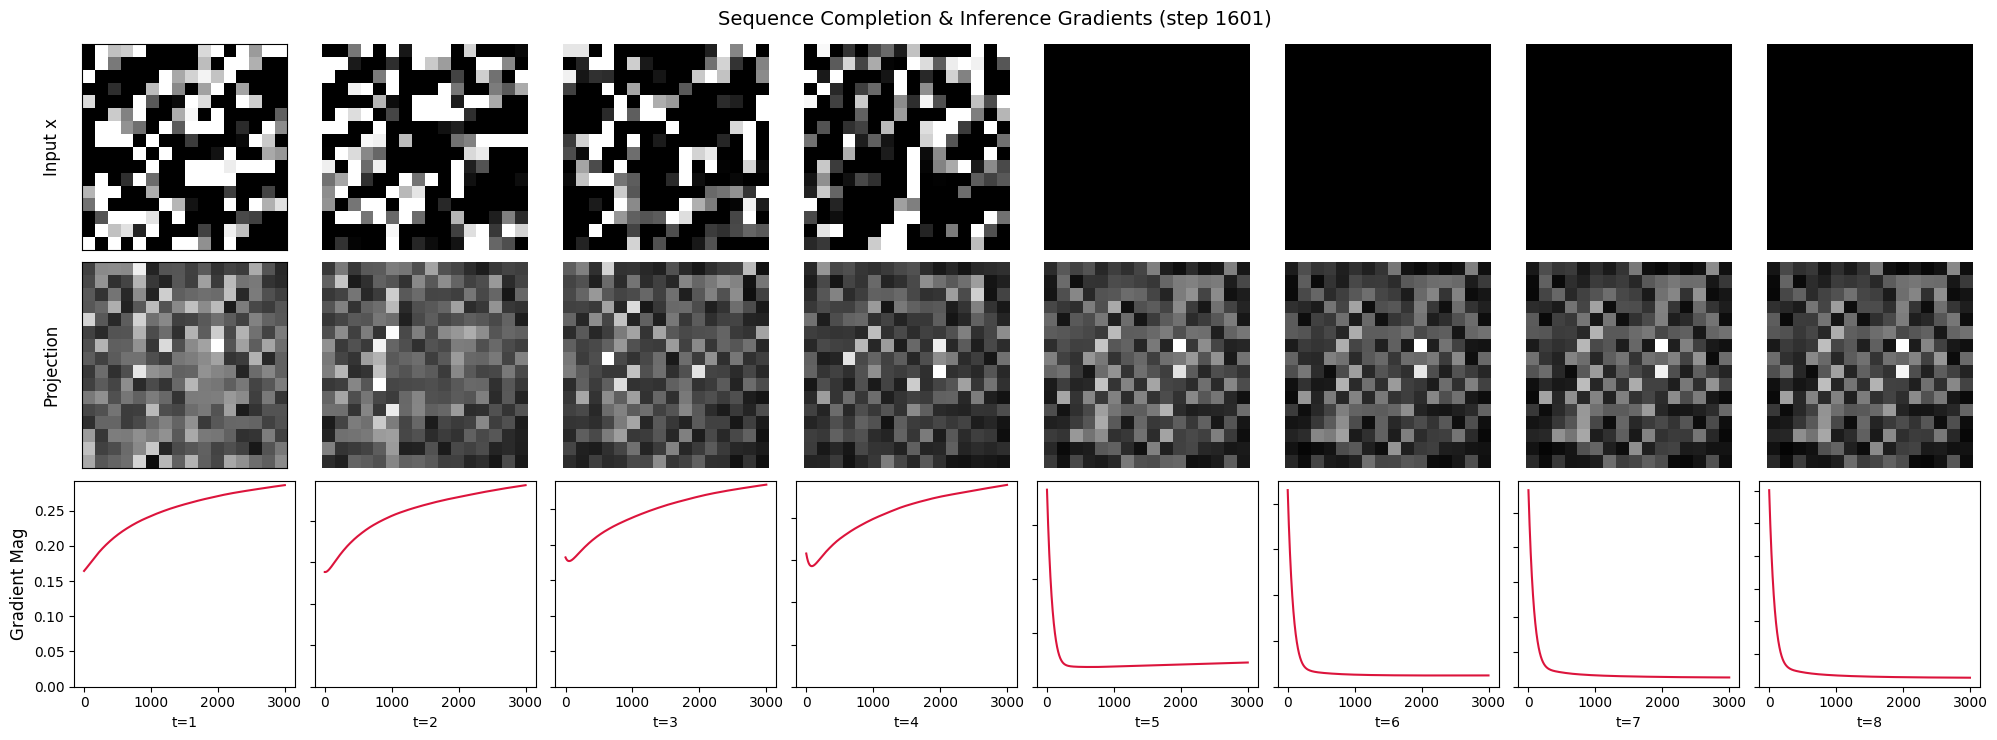

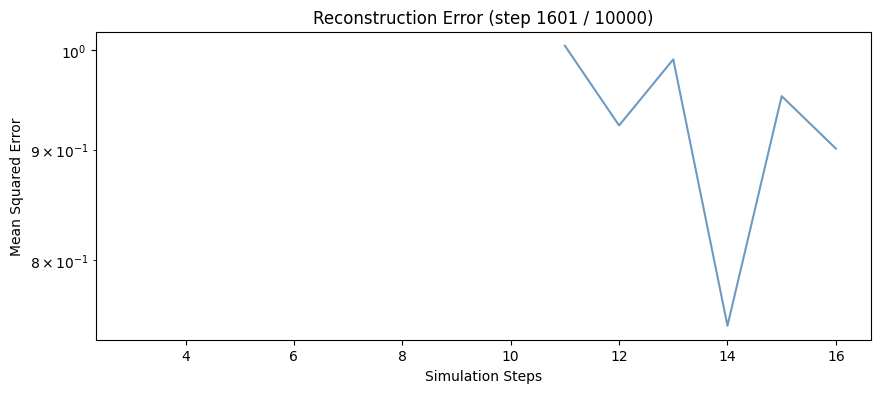

Training Progress:   1%|          | 100/10000 [09:39<10:25:21,  3.79s/it]/tmp/ipykernel_15166/1338896386.py:20: RuntimeWarning: invalid value encountered in scalar divide
  return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))
Training Progress:   2%|▏         | 200/10000 [17:07<13:15:37,  4.87s/it]/tmp/ipykernel_15166/1338896386.py:20: RuntimeWarning: invalid value encountered in scalar divide
  return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))
Training Progress:   4%|▍         | 400/10000 [31:47<11:37:50,  4.36s/it]/tmp/ipykernel_15166/1338896386.py:20: RuntimeWarning: invalid value encountered in scalar divide
  return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))
Training Progress:   5%|▌         | 500/10000 [39:11<10:29:22,  3.97s/it]/tmp/ipykernel_15166/1338896386.py:20: RuntimeWarning: invalid value encountered in scalar divide
  return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))
Training Progress:   6%|▌         | 600/10000 [46:11<11:02:3

In [ ]:
#create a linear network with 50 units and change the w_rule rule accordingly (hebbian, bcm_abs, perceptron)
network_params = LateralInhibitoryLayer.default_hparams(vg.get_shape())
network_params['activation'] = 'relu'
network_params['num_units_y'] = 1000
network_params['gradient'] = 'voltage-jax'
network_params['w_update'] = 'perceptron'
network_params['w_rectify'] = True
network_params['w_seed'] = 42
network_params['w_init'] = 'random'
network_params['w_dynamic'] = True
network_params['m_update'] = 'hebbian'
network_params['m_rectify'] = True
network_params['m_init'] = 'random'
network_params['m_dynamic'] = True
network_params['p_update'] = 'perceptron'
network_params['p_rectify'] = True
network_params['p_init'] = 'random'
network_params['p_dynamic'] = True
network_params['p_zero_dig'] = True
network_params['num_steps'] = 1000
network_params['multisteps'] = 3
network_params['step'] = 0.01
network_params['normalize_input'] = True
network_params['normalize_w_weights'] = True
network_params['normalize_p_weights'] = True
network_params['zero_sequence'] = 'zero'
network_params['zero_epoch'] = 'zero'
network_params['memory_size'] = 1

network = LateralInhibitoryLayer(network_params)

num_steps = 10000
num_tests = 5
eval_every = 100
sequence_size = 8
synaptic_input_distance_from_identity_perceptron, distance_from_identity_perceptron, consistency_error_perceptron, second_moment_estimate_perceptron, mse_error_perceptron = train_network(network, vg, num_steps, num_tests, sequence_size, eval_every)